# K20 exploratory feature analysis
These plots use the already selected initial XGBoost and Extra Trees configurations. Error bars show sample SD across the three held-out folds. Features are numbered from 1. These development folds were previously used in model exploration.

findfont: Failed to find font weight normal for Helvetica, now using medium.


findfont: Font family ['serif'] not found. Falling back to Helvetica.


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


findfont: Failed to find font weight normal for Helvetica, now using medium.


findfont: Failed to find font weight normal for Helvetica, now using medium.


findfont: Font family ['serif'] not found. Falling back to Helvetica.


... (90 outputs left out)

findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


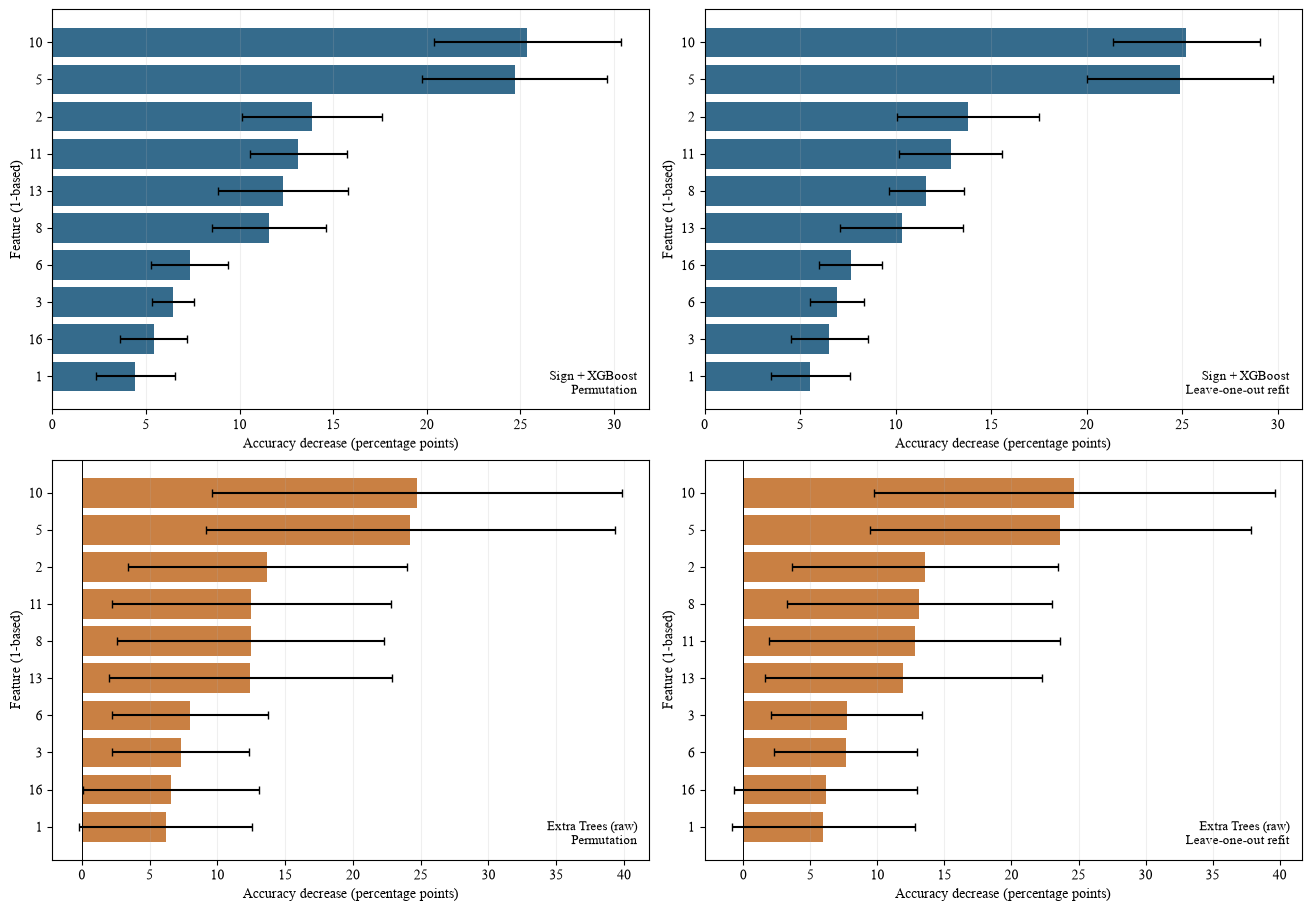

In [1]:
import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().resolve()
if root.name == 'B_Traditional_ML':
    root = root.parent
out = root / 'B_Traditional_ML' / 'results' / 'model_analysis'
def read(name):
    with (out / name).open(encoding='utf-8', newline='') as f:
        return list(csv.DictReader(f))
perm, lofo = read('permutation_importance.csv'), read('leave_one_feature_out.csv')
models = [('xgb_sign_child1_s1', 'Sign + XGBoost'), ('extra_leaf2_features1.0', 'Extra Trees (raw)')]
def fold_values(rows, model, feature):
    return [np.mean([float(r['accuracy_drop']) for r in rows if r['id'] == model and int(r['feature_one_based']) == feature and int(r['fold']) == fold]) for fold in range(3)]
plt.rcParams.update({'pdf.use14corefonts': True, 'font.family': 'serif', 'font.serif': ['Times New Roman']})
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for i, (model, label) in enumerate(models):
    for j, (rows, method) in enumerate(((perm, 'Permutation'), (lofo, 'Leave-one-out refit'))):
        values = np.array([fold_values(rows, model, feature) for feature in range(1, 21)])
        means = values.mean(axis=1) * 100
        sd = values.std(axis=1, ddof=1) * 100
        order = np.argsort(means)[-10:]
        ax = axes[i, j]
        ax.barh(np.arange(10), means[order], xerr=sd[order], capsize=3, color=('#356b8c' if i == 0 else '#c98043'))
        ax.set_yticks(np.arange(10), [str(x + 1) for x in order])
        ax.set_xlabel('Accuracy decrease (percentage points)')
        ax.set_ylabel('Feature (1-based)')
        ax.text(.98, .03, label + '\n' + method, ha='right', va='bottom', transform=ax.transAxes, fontsize=9)
        ax.axvline(0, color='black', linewidth=.7)
        ax.grid(axis='x', alpha=.2)
fig_dir = out / 'figures'
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / 'feature_analysis.png', dpi=180)
fig.savefig(fig_dir / 'feature_analysis.pdf')
plt.show()
